# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [46]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy as scp

from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList
from tof_helper_functions.tof_simulation_objects import Chopper, Detector
#plt.style.use('stylesheet.mplstyle')

In [47]:
def maxwell(x,a,sigma):
    return a * x**2 / sigma**3 *np.exp(-(x)**2/(2*sigma**2))

In [48]:
# generate maxwellian spectrum N(bin)
n = 4000
n_max =  n-1
a = 1000000
sigma = 400

print(f"mean = {2*a*sigma}")

x_list = np.linspace(0,n_max,n)
maxwell_signal_list = maxwell(x_list, a, sigma)

mean = 800000000


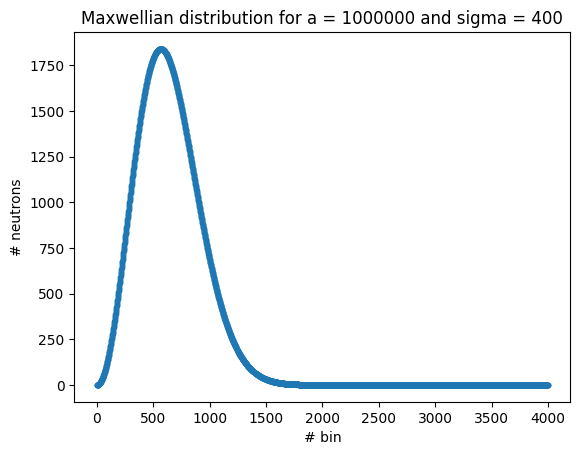

In [49]:
# feed the maxwellian signal into the TOF framework
rawTOF_maxwellian = RawTOFPointList(maxwell_signal_list, 
                         s=631, 
                         label = "Poissonian")
v_max = 18.5
v_min = 3.5
v_step = 0.05
rebinnedTOF_maxwellian = RebinnedTOFPointList(rawTOF_maxwellian,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned Maxwellian")


plt.plot(rawTOF_maxwellian.bin_number, rawTOF_maxwellian.N_bin, marker='.') 
plt.xlabel("# bin")
plt.ylabel("# neutrons")
plt.title(f"Maxwellian distribution for a = {a} and sigma = {sigma}")
#plt.legend()
plt.show()

In [50]:
# chopper cycle open for 20 m and close for 380 ms
chopper_cycle_time_ms = 400
chopper_open_time_ms = 20
num_chop = 747 # found to have good numerical stability with medium runtime

ONE_SIGMA = 0.6827
t_convolution_offset_err_multiplikator = 1.0
t_convolution_offset = chopper_open_time_ms / 2.0

v_low_gaussfit, v_high_gaussfit = 6.0, 11.0

multiplicator_low = -1
multiplicator_high = 1
multiplicator_n = 25

t_convolution_offset_err_multiplicator_list = np.logspace(multiplicator_low, multiplicator_high, multiplicator_n)
print(t_convolution_offset_err_multiplicator_list)
print(f"expected simulation time: {np.sum(num_chop*len(t_convolution_offset_err_multiplicator_list))/6500.0:.2f} min")

[ 0.1         0.12115277  0.14677993  0.17782794  0.21544347  0.26101572
  0.31622777  0.38311868  0.46415888  0.56234133  0.68129207  0.82540419
  1.          1.21152766  1.46779927  1.77827941  2.15443469  2.61015722
  3.16227766  3.83118685  4.64158883  5.62341325  6.81292069  8.25404185
 10.        ]
expected simulation time: 2.87 min


In [51]:
v_peak_difference_in_sigmas_noeep_list = []
v_peak_difference_in_sigmas_eep_list = []
v_mean_difference_in_sigmas_noeep_list = []
v_mean_difference_in_sigmas_eep_list = []
v_rms_difference_in_sigmas_noeep_list = []
v_rms_difference_in_sigmas_eep_list = []

v_peak_relative_err_list = []
v_mean_relative_err_list = []
v_rms_relative_err_list = []

for i in t_convolution_offset_err_multiplicator_list:

    t_convolution_offset_err = t_convolution_offset * i*ONE_SIGMA

    chopper1 = Chopper("Chopper 1", num_chop=num_chop, t_open_ms=chopper_open_time_ms, t_close_ms=chopper_cycle_time_ms-chopper_open_time_ms)
    chopper1.renormalize_opening_function()

    # detector
    detector1 = Detector(num_bins=4000, 
                        s_mm=639, 
                        do_cycle=False,
                        do_gaussian_noise=True,
                        sigma = 50)
    detector1.measure(rawTOF_maxwellian, chopper1)

    rawTOF_maxwellian_convoluted = RawTOFPointList(detector1.data, 
                            s=631, 
                            label = "Convoluted",
                            convolution_t=t_convolution_offset)

    rebinnedTOF_maxwellian_convoluted = RebinnedTOFPointList(rawTOF_maxwellian_convoluted,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "Rebinned convoluted")

    rawTOF_maxwellian_convoluted_eep = RawTOFPointList(detector1.data, 
                            s=631, 
                            label = "Convoluted, eep",
                            convolution_t=t_convolution_offset,
                            convolution_t_err=t_convolution_offset_err)

    rebinnedTOF_maxwellian_convoluted_eep = RebinnedTOFPointList(rawTOF_maxwellian_convoluted_eep,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "Rebinned convoluted, eep")

    # analyze the pure spectrum and the spectrum after convolution by fitting a gauss to the peak
    v_peak_maxwell, v_peak_maxwell_err = rebinnedTOF_maxwellian.find_peak_velocity(gausstype='threepoints', 
                                                                            v_low=v_low_gaussfit, 
                                                                            v_high=v_high_gaussfit, 
                                                                            a0 = 250000.0, 
                                                                            mu0= 8.0, 
                                                                            sigma0=1.0)
    v_peak_convoluted, v_peak_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_peak_velocity(gausstype='threepoints', 
                                                                                            v_low=v_low_gaussfit, 
                                                                                            v_high=v_high_gaussfit, 
                                                                                            a0 = 250000.0, 
                                                                                            mu0= 8.0, 
                                                                                            sigma0=1.0)
    v_peak_convoluted_eep, v_peak_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_peak_velocity(gausstype='threepoints', 
                                                                                            v_low=v_low_gaussfit, 
                                                                                            v_high=v_high_gaussfit, 
                                                                                            a0 = 250000.0, 
                                                                                            mu0= 8.0, 
                                                                                            sigma0=1.0)

    v_mean_maxwell, v_mean_maxwell_err = rebinnedTOF_maxwellian.find_mean_velocity()
    v_mean_convoluted, v_mean_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_mean_velocity()
    v_mean_convoluted_eep, v_mean_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_mean_velocity()

    v_rms_maxwell, v_rms_maxwell_err = rebinnedTOF_maxwellian.find_rms_velocity()
    v_rms_convoluted, v_rms_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_rms_velocity()
    v_rms_convoluted_eep, v_rms_convoluted_eep_err = rebinnedTOF_maxwellian_convoluted_eep.find_rms_velocity()

    v_peak_relative_err_list.append(v_peak_convoluted_eep_err / v_peak_convoluted_eep)
    v_mean_relative_err_list.append(v_mean_convoluted_eep_err / v_mean_convoluted_eep)
    v_rms_relative_err_list.append(v_rms_convoluted_eep_err / v_rms_convoluted_eep)

    v_peak_difference_in_sigmas_noeep_list.append(np.abs(v_peak_maxwell - v_peak_convoluted) / np.sqrt(v_peak_maxwell_err**2 + v_peak_convoluted_err**2))
    v_peak_difference_in_sigmas_eep_list.append(np.abs(v_peak_maxwell - v_peak_convoluted_eep) / np.sqrt(v_peak_maxwell_err**2 + v_peak_convoluted_eep_err**2))

    v_mean_difference_in_sigmas_noeep_list.append(np.abs(v_mean_maxwell - v_mean_convoluted) / np.sqrt(v_mean_maxwell_err**2 + v_mean_convoluted_err**2))
    v_mean_difference_in_sigmas_eep_list.append(np.abs(v_mean_maxwell - v_mean_convoluted_eep) / np.sqrt(v_mean_maxwell_err**2 + v_mean_convoluted_eep_err**2))

    v_rms_difference_in_sigmas_noeep_list.append(np.abs(v_rms_maxwell - v_rms_convoluted) / np.sqrt(v_rms_maxwell_err**2 + v_rms_convoluted_err**2))
    v_rms_difference_in_sigmas_eep_list.append(np.abs(v_rms_maxwell - v_rms_convoluted_eep) / np.sqrt(v_rms_maxwell_err**2 + v_rms_convoluted_eep_err**2))

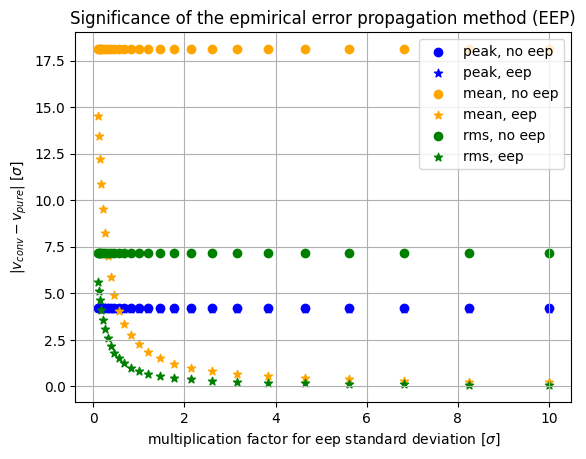

In [52]:
x = t_convolution_offset_err_multiplicator_list
xlabel = r"multiplication factor for eep standard deviation [$\sigma$]"
plt.scatter(x, v_peak_difference_in_sigmas_noeep_list, label="peak, no eep", color="b")
plt.scatter(x, v_peak_difference_in_sigmas_eep_list, label="peak, eep", color="b", marker='*')
plt.scatter(x, v_mean_difference_in_sigmas_noeep_list, label="mean, no eep", color="orange")
plt.scatter(x, v_mean_difference_in_sigmas_eep_list, label="mean, eep", color="orange", marker='*')
plt.scatter(x, v_rms_difference_in_sigmas_noeep_list, label="rms, no eep", color="g")
plt.scatter(x, v_rms_difference_in_sigmas_eep_list, label="rms, eep", color="g", marker='*')
plt.xlabel(xlabel)
plt.ylabel(r"|$v_{conv}-v_{pure}$| [$\sigma$]")
plt.legend()
plt.grid(True)
plt.title(f"Significance of the epmirical error propagation method (EEP)")
plt.show()

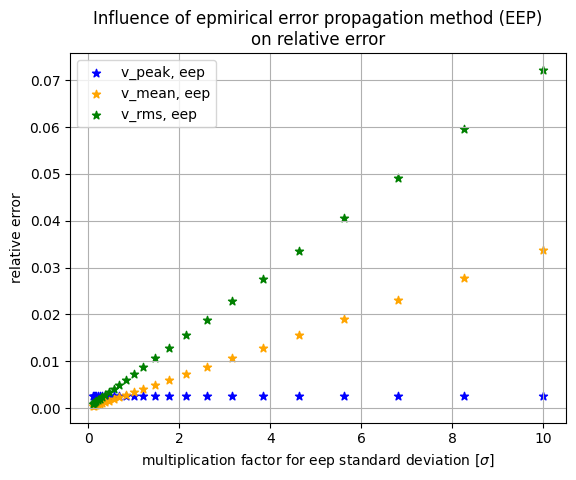

In [53]:
x = t_convolution_offset_err_multiplicator_list
xlabel = r"multiplication factor for eep standard deviation [$\sigma$]"
plt.scatter(x, v_peak_relative_err_list, label="v_peak, eep", color="b", marker='*')
plt.scatter(x, v_mean_relative_err_list, label="v_mean, eep", color="orange", marker='*')
plt.scatter(x, v_rms_relative_err_list, label="v_rms, eep", color="g", marker='*')
plt.xlabel(xlabel)
plt.ylabel("relative error")
plt.legend()
plt.grid(True)
plt.title(f"Influence of epmirical error propagation method (EEP)\non relative error")
plt.show()